本 notebook 是 [M02.4 数理统计](../notes/04-mathematical-statistics.qmd) 的实例讲解。

1. 1. 估计量的偏差、方差与 MSE
2. 2. 置信区间的覆盖率
3. 3. Bootstrap 与多重检验
4. 4. 从似然到后验

在 VS Code 中选择仓库 `.venv` 内核，逐单元运行；运行结果随文件保存。示例使用固定随机种子和合成数据。

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib_inline.backend_inline import set_matplotlib_formats
from scipy.stats import beta, bootstrap, false_discovery_control, t

from semiai.plotting import BLUE, MUTED, ORANGE, use_style

use_style()
set_matplotlib_formats("svg")
rng = np.random.default_rng(42)

## 1. 估计量的偏差、方差与 MSE

重复生成小样本，比较高斯方差的最大似然估计与无偏估计。一次数据集的估计值不能直接揭示估计量的偏差。

In [2]:
samples = rng.normal(2, 2, size=(10000, 10))
v_mle = samples.var(axis=1, ddof=0)
v_unbiased = samples.var(axis=1, ddof=1)
rows = []
for name, est in [("MLE", v_mle), ("unbiased", v_unbiased)]:
    bias = est.mean() - 4
    variance = est.var()
    mse = np.mean((est - 4) ** 2)
    rows.append((name, bias, variance, mse))
    assert np.allclose(mse, variance + bias**2)
print(pd.DataFrame(rows, columns=["estimator", "bias", "variance", "MSE"]))

  estimator      bias  variance       MSE
0       MLE -0.374181  3.003207  3.143219
1  unbiased  0.028687  3.707663  3.708486


读法：无偏不保证 MSE 最小；减少偏差有时会增加方差。这里的分解是对重复抽样分布而言，而不是同一份数据上的样本残差分解。

## 2. 置信区间的覆盖率

先画出多次实验各自的区间，再扩大重复次数，直接测量包含固定真均值的比例。

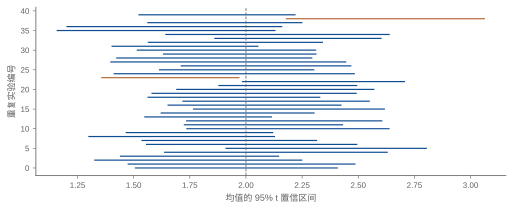

重复次数: 6000 经验覆盖率: 0.9493333333333334


In [3]:
samples = rng.normal(2.0, 1.0, size=(40, 25))
means = samples.mean(axis=1)
half = t.ppf(0.975, 24) * samples.std(axis=1, ddof=1) / 5
contains = np.abs(means - 2) <= half
fig, ax = plt.subplots(figsize=(7.2, 3.0))
for i, (mu, h, ok) in enumerate(zip(means, half, contains, strict=True)):
    ax.plot([mu - h, mu + h], [i, i], color=BLUE if ok else ORANGE, lw=1.2)
ax.axvline(2, color=MUTED, ls="--", lw=0.8)
ax.set(xlabel="均值的 95% t 置信区间", ylabel="重复实验编号")
fig.tight_layout()
plt.show()

trials = rng.normal(2, 1, size=(6000, 25))
mean = trials.mean(axis=1)
half = t.ppf(0.975, 24) * trials.std(axis=1, ddof=1) / 5
coverage = np.mean(np.abs(mean - 2) <= half)
print("重复次数:", len(trials), "经验覆盖率:", coverage)
assert abs(coverage - 0.95) < 0.025

读法：随机的是区间端点，真参数在频率学派模型中固定。单次得到的区间不具有“参数以 95% 概率在内”的频率学派解释。

## 3. Bootstrap 与多重检验

以重采样近似统计量的抽样波动；随后在全部原假设为真的实验中比较多重检验校正。

In [4]:
x = rng.exponential(scale=2, size=70)
res = bootstrap((x,), np.median, n_resamples=2000, method="BCa", rng=np.random.default_rng(5))
print("中位数:", np.median(x), "BCa 区间:", res.confidence_interval)
pvalues = rng.random((6000, 20))
raw = (pvalues < 0.05).any(axis=1).mean()
bonf = (pvalues < 0.05 / 20).any(axis=1).mean()
bh = (false_discovery_control(pvalues, axis=1, method="bh") < 0.05).any(axis=1).mean()
print(
    pd.DataFrame(
        {"rule": ["uncorrected", "Bonferroni", "BH"], "P(any false rejection)": [raw, bonf, bh]}
    )
)
print("未校正解析值:", 1 - 0.95**20)

中位数: 1.2954643645948567 BCa 区间: ConfidenceInterval(low=np.float64(0.9997960179559222), high=np.float64(1.8124213970027916))
          rule  P(any false rejection)
0  uncorrected                0.646500
1   Bonferroni                0.042833
2           BH                0.043167
未校正解析值: 0.6415140775914581


读法：原假设全真时，任何拒绝都是误报，FDR 等于出现至少一次拒绝的概率。这是特殊情形；一般情况下 FWER 与 FDR 控制不同的量。独立样本 Bootstrap 不能直接用于相关轨迹帧。

## 4. 从似然到后验

对二项观测使用 Beta 先验，计算 MLE、MAP、后验均值与可信区间。

In [5]:
successes = 8
n = 20
a0 = 2
b0 = 2
a = a0 + successes
b = b0 + n - successes
print("MLE:", successes / n, "MAP:", (a - 1) / (a + b - 2), "后验均值:", a / (a + b))
print("95% 后验等尾可信区间:", beta.ppf([0.025, 0.975], a, b))
assert np.allclose(a / (a + b), (a0 + successes) / (a0 + b0 + n))

MLE: 0.4 MAP: 0.4090909090909091 后验均值: 0.4166666666666667
95% 后验等尾可信区间: [0.2319142  0.61458104]


读法：MAP 是后验密度的最大点，后验均值是平方损失下的贝叶斯估计；它们代表不同决策准则，参数变换后也不应混为一谈。

## 小结

估计量的质量由偏差、方差和目标损失共同决定。区间与检验必须附着在明确的抽样模型上，多重比较需要对应的错误率控制。贝叶斯方法提供后验概率，但仍需明确先验、似然与决策准则。